#  Model A — Unsupervised Learning
### Intelligent Reading Comprehension System


## 1.  Import Libraries

In [1]:
import os
import time
import warnings

import pandas as pd
import numpy as np
import scipy.sparse as sparse

from sklearn.cluster import MiniBatchKMeans
from sklearn.decomposition import TruncatedSVD
from sklearn.metrics import (
    silhouette_score,
    calinski_harabasz_score,
    davies_bouldin_score
)

import matplotlib.pyplot as plt
import joblib

warnings.filterwarnings("ignore")

## 2.  Load TF-IDF Feature Matrix

In [2]:
X_train = sparse.load_npz('../data/processed/X_train_tfidf.npz')

print(f"Feature matrix shape: {X_train.shape}")

Feature matrix shape: (281168, 5000)


## 3.  Dimensionality Reduction via TruncatedSVD


In [3]:
svd = TruncatedSVD(n_components=100, random_state=42)

X_reduced = svd.fit_transform(X_train)

print(f"Reduced shape: {X_reduced.shape}")

Reduced shape: (281168, 100)


## 4.  Train MiniBatch K-Means

In [4]:
kmeans = MiniBatchKMeans(
    n_clusters=4,
    random_state=42,
    batch_size=2048,
    n_init="auto"
)

start = time.time()
kmeans.fit(X_reduced)
elapsed = time.time() - start

cluster_labels = kmeans.labels_

print(f"Training time : {elapsed:.2f} seconds")

Training time : 4.94 seconds


## 5.  Cluster Distribution

In [5]:
cluster_counts = pd.Series(cluster_labels).value_counts().sort_index()

cluster_counts.rename(index=lambda x: f"Cluster {x}").to_frame("Count")

,Count
Cluster 0,36837
Cluster 1,151586
Cluster 2,23492
Cluster 3,69253


## 6.  Evaluate Cluster Quality


In [6]:
np.random.seed(42)
idx = np.random.choice(X_reduced.shape[0], size=10000, replace=False)

X_sample      = X_reduced[idx]
labels_sample = cluster_labels[idx]

silhouette = silhouette_score(X_sample, labels_sample)
calinski   = calinski_harabasz_score(X_sample, labels_sample)
davies     = davies_bouldin_score(X_sample, labels_sample)

print(f"Silhouette Score        : {silhouette:.4f}")
print(f"Calinski-Harabasz Score : {calinski:.4f}")
print(f"Davies-Bouldin Score    : {davies:.4f}")
print(f"Training Time           : {elapsed:.2f} sec")

Silhouette Score        : 0.0381
Calinski-Harabasz Score : 219.9774
Davies-Bouldin Score    : 4.8373
Training Time           : 4.94 sec


## 7.  2D Cluster Visualization

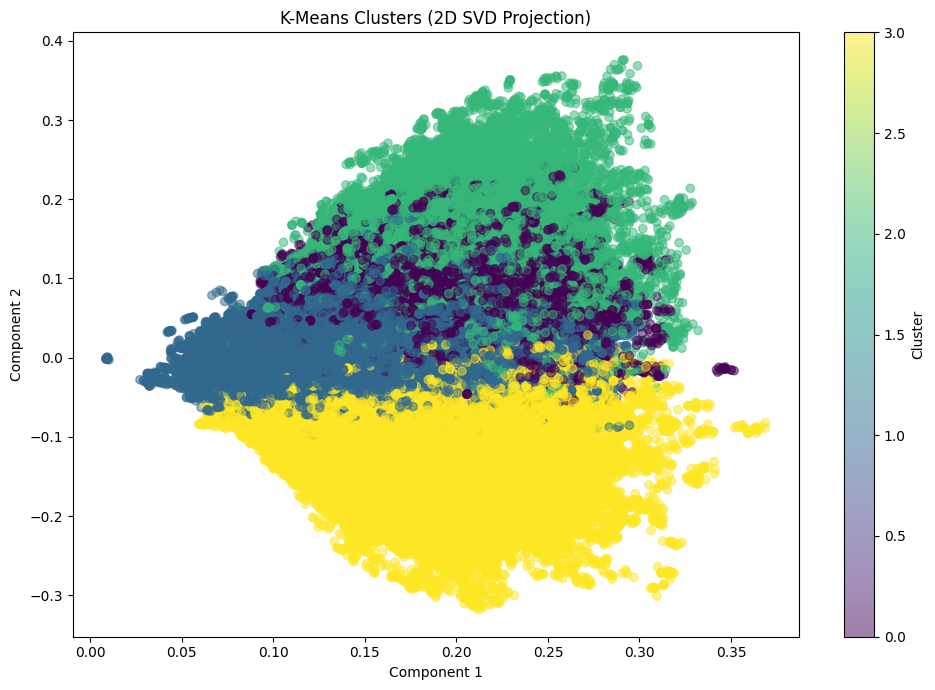

In [7]:
svd_2d = TruncatedSVD(n_components=2, random_state=42)
X_2d   = svd_2d.fit_transform(X_train)

plt.figure(figsize=(10, 7))

scatter = plt.scatter(X_2d[:, 0], X_2d[:, 1], c=cluster_labels, alpha=0.5)

plt.title("K-Means Clusters (2D SVD Projection)")
plt.xlabel("Component 1")
plt.ylabel("Component 2")
plt.colorbar(scatter, label="Cluster")

os.makedirs('../reports/figures', exist_ok=True)
plt.savefig('../reports/figures/kmeans_clusters.png', dpi=150, bbox_inches='tight')

plt.tight_layout()
plt.show()

## 8.  Save Results & Models

In [8]:
os.makedirs('../reports', exist_ok=True)
os.makedirs('../models/unsupervised', exist_ok=True)

# Results table
results_df = pd.DataFrame({
    'Metric': ['Silhouette Score', 'Calinski-Harabasz Score', 'Davies-Bouldin Score', 'Training Time (sec)'],
    'Value':  [silhouette, calinski, davies, elapsed]
})
results_df.to_csv('../reports/model_b_unsupervised_results.csv', index=False)

# Trained models
joblib.dump(kmeans, '../models/unsupervised/kmeans_model.pkl')
joblib.dump(svd,    '../models/unsupervised/svd_model.pkl')

print("Artifacts saved:")
print("  ../reports/model_b_unsupervised_results.csv")
print("  ../reports/figures/kmeans_clusters.png")
print("  ../models/unsupervised/kmeans_model.pkl")
print("  ../models/unsupervised/svd_model.pkl")

Artifacts saved:
  ../reports/model_b_unsupervised_results.csv
  ../reports/figures/kmeans_clusters.png
  ../models/unsupervised/kmeans_model.pkl
  ../models/unsupervised/svd_model.pkl
